In [1]:
!pip install annoy

Exact NN index: [219 898 593]
Exact NN jarak: [0.         1.36915938 2.27931544]
Waktu Exact: 3.4628 ms

Annoy NN index: [219, 898, 593]
Annoy NN jarak: [np.float64(0.0), np.float64(1.369159376273702), np.float64(2.2793154441691197)]
Waktu Annoy: 0.4282 ms


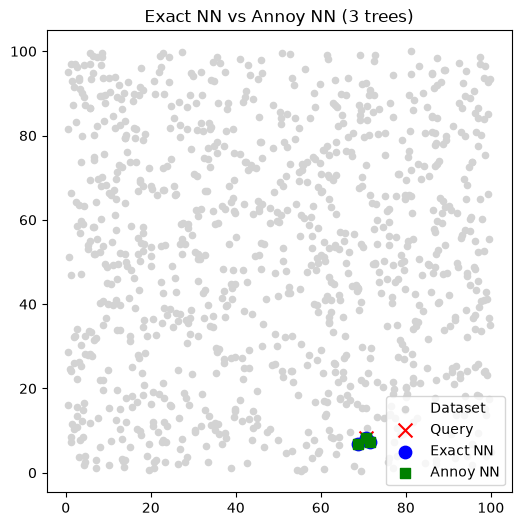

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import time

from annoy import AnnoyIndex

# 1. Dataset 2D
np.random.seed(42)
n_points = 1000
X = np.random.rand(n_points, 2) * 100  # titik random dalam ruang 100x100

# Query point (ambil salah satu titik random)
query = X[np.random.randint(0, n_points)]

# 2. Exact NN (brute force)
start = time.time()
distances = np.linalg.norm(X - query, axis=1)
idx_exact = np.argsort(distances)[:3]  # ambil 3 terdekat
time_exact = time.time() - start

print("Exact NN index:", idx_exact)
print("Exact NN jarak:", distances[idx_exact])
print("Waktu Exact:", round(time_exact*1000, 4), "ms")

# 3. Annoy NN (3 tree)
f = 2  # dimensi
t = AnnoyIndex(f, 'euclidean')
for i, vec in enumerate(X):
    t.add_item(i, vec)

t.build(3)  # 3 trees

start = time.time()
idx_ann = t.get_nns_by_vector(query, 3)  # cari 3 NN
time_ann = time.time() - start

print("\nAnnoy NN index:", idx_ann)
print("Annoy NN jarak:", [np.linalg.norm(X[i]-query) for i in idx_ann])
print("Waktu Annoy:", round(time_ann*1000, 4), "ms")

# 4. Visualisasi hasil
plt.figure(figsize=(6,6))
plt.scatter(X[:,0], X[:,1], c="lightgray", s=20, label="Dataset")
plt.scatter(query[0], query[1], c="red", marker="x", s=100, label="Query")

# Exact NN ditandai biru
plt.scatter(X[idx_exact,0], X[idx_exact,1], c="blue", s=80, label="Exact NN")

# Annoy NN ditandai hijau
plt.scatter(X[idx_ann,0], X[idx_ann,1], c="green", s=50, marker="s", label="Annoy NN")

plt.legend()
plt.title("Exact NN vs Annoy NN (3 trees)")
plt.show()

In [3]:
import numpy as np
import time
from annoy import AnnoyIndex

# Daftar konfigurasi sesuai tabel
configs = [
    {"metric": "euclidean", "n_trees": 3, "n_points": 1000},
    {"metric": "euclidean", "n_trees": 8, "n_points": 1000},
    {"metric": "euclidean", "n_trees": 3, "n_points": 100000},
    {"metric": "angular", "n_trees": 3, "n_points": 1000},
    {"metric": "angular", "n_trees": 8, "n_points": 1000},
    {"metric": "angular", "n_trees": 3, "n_points": 100000},
]

for cfg in configs:
    np.random.seed(42)
    n_points = cfg["n_points"]
    metric = cfg["metric"]
    n_trees = cfg["n_trees"]

    # 1. Dataset 2D
    X = np.random.rand(n_points, 2) * 100
    query = X[np.random.randint(0, n_points)]

    # 2. Exact NN (Brute Force)
    start = time.time()
    if metric == 'euclidean':
        distances = np.linalg.norm(X - query, axis=1)
    else: # angular
        dot = np.dot(X, query)
        norms = np.linalg.norm(X, axis=1) * np.linalg.norm(query)
        distances = 1.0 - (dot / norms)

    idx_exact = np.argsort(distances)[:3]
    time_exact = (time.time() - start) * 1000

    # 3. Annoy NN
    f = 2
    t = AnnoyIndex(f, metric)
    for i, vec in enumerate(X):
        t.add_item(i, vec)
    t.build(n_trees)

    start = time.time()
    idx_ann = t.get_nns_by_vector(query, 3)
    time_ann = (time.time() - start) * 1000

    # Print Hasil untuk Tabel
    print(f"Metric: {metric.capitalize()} | Trees: {n_trees} | Data: {n_points}")
    print(f"  -> Index ENN vs ANN : {idx_exact} vs {idx_ann}")
    print(f"  -> Waktu (ms) ENN vs ANN: {time_exact:.4f} vs {time_ann:.4f}\n")

Metric: Euclidean | Trees: 3 | Data: 1000
  -> Index ENN vs ANN : [219 898 593] vs [219, 898, 593]
  -> Waktu (ms) ENN vs ANN: 0.5121 vs 0.0739

Metric: Euclidean | Trees: 8 | Data: 1000
  -> Index ENN vs ANN : [219 898 593] vs [219, 898, 593]
  -> Waktu (ms) ENN vs ANN: 0.5753 vs 0.0956

Metric: Euclidean | Trees: 3 | Data: 100000
  -> Index ENN vs ANN : [64040 64186 88792] vs [64040, 64186, 88792]
  -> Waktu (ms) ENN vs ANN: 10.1712 vs 0.0277

Metric: Angular | Trees: 3 | Data: 1000
  -> Index ENN vs ANN : [219 429 540] vs [219, 429, 962]
  -> Waktu (ms) ENN vs ANN: 5.9564 vs 0.0377

Metric: Angular | Trees: 8 | Data: 1000
  -> Index ENN vs ANN : [219 429 540] vs [219, 429, 540]
  -> Waktu (ms) ENN vs ANN: 0.1175 vs 0.1259

Metric: Angular | Trees: 3 | Data: 100000
  -> Index ENN vs ANN : [64040  1310  1267] vs [7452, 64040, 72632]
  -> Waktu (ms) ENN vs ANN: 10.0002 vs 0.0286



In [3]:
import numpy as np
import time
from sklearn.metrics.pairwise import euclidean_distances
from annoy import AnnoyIndex

# ---- 1. Buat dataset mirip Spotify ----
n_tracks = 1_000_000   # 1 juta track
n_features = 20        # contoh: danceability, energy, tempo, dll.

# dataset besar (random untuk simulasi)
X = np.random.rand(n_tracks, n_features).astype(np.float32)

# query track (misalnya lagu baru)
query = np.random.rand(1, n_features).astype(np.float32)

# ---- 2. Exact NN (brute force) ----
start = time.time()
distances = euclidean_distances(query, X)[0]   # hitung semua jarak
exact_idx = np.argsort(distances)[:5]          # ambil 5 terdekat
exact_time = time.time() - start

print("Exact NN result:", exact_idx)
print("Exact NN time:", round(exact_time, 3), "seconds")

# ---- 3. Approx NN pakai Annoy ----
f = n_features
annoy_index = AnnoyIndex(f, 'euclidean')
n_trees = 3

# build index
for i in range(n_tracks):
    annoy_index.add_item(i, X[i])
annoy_index.build(n_trees)

start = time.time()
annoy_idx = annoy_index.get_nns_by_vector(query[0], 5)  # ambil 5 lagu yang mirip
annoy_time = time.time() - start

print("Annoy result:", annoy_idx)
print("Annoy time:", round(annoy_time, 3), "seconds")


Exact NN result: [507707 440426 428036 194367 745120]
Exact NN time: 0.537 seconds
Annoy result: [335111, 795137, 698741, 506150, 759834]
Annoy time: 0.0 seconds


In [4]:
# Install annoy terlebih dahulu jika belum ada
!pip install annoy -q

import numpy as np
import time
from annoy import AnnoyIndex

# Konfigurasi parameter sesuai tabel
n_tracks = 1_000_000
n_features = 20
n_trees = 8
k_neighbors = 5

# Membuat dataset dan query acak
np.random.seed(42)
X = np.random.rand(n_tracks, n_features).astype(np.float32)
query = np.random.rand(1, n_features).astype(np.float32)

metrics = ['euclidean', 'angular']

for metric in metrics:
    # 1. Exact NN (Brute Force)
    start = time.time()
    if metric == 'euclidean':
        distances = np.linalg.norm(X - query, axis=1)
    else: # angular
        dot = np.dot(X, query[0])
        norms = np.linalg.norm(X, axis=1) * np.linalg.norm(query[0])
        distances = 1.0 - (dot / (norms + 1e-10))
        
    exact_idx = np.argsort(distances)[:k_neighbors]
    exact_time = time.time() - start

    # 2. Annoy NN
    t = AnnoyIndex(n_features, metric)
    for i in range(n_tracks):
        t.add_item(i, X[i])
    t.build(n_trees)

    start = time.time()
    ann_idx = t.get_nns_by_vector(query[0], k_neighbors)
    ann_time = time.time() - start

    # Cetak hasil untuk mengisi baris tabel
    print(f"Metric: {metric.capitalize()} | Tree: {n_trees} | Data: {n_tracks:,}")
    print(f"  - Hasil Index ENN vs ANN : {exact_idx} vs {ann_idx}")
    print(f"  - Waktu (detik) ENN vs ANN: {exact_time:.4f} s vs {ann_time:.4f} s\n")

Metric: Euclidean | Tree: 8 | Data: 1,000,000
  - Hasil Index ENN vs ANN : [229350 553886 763448 256344 308000] vs [308000, 240885, 449519, 397639, 980706]
  - Waktu (detik) ENN vs ANN: 0.9042 s vs 0.0002 s

Metric: Angular | Tree: 8 | Data: 1,000,000
  - Hasil Index ENN vs ANN : [308000 376840 229350 763448 553886] vs [308000, 229350, 975035, 85376, 409243]
  - Waktu (detik) ENN vs ANN: 0.5292 s vs 0.0007 s



In [6]:
!pip install faiss-cpu
#!pip install faiss-gpu

Exact NN (Flat) indices: [[137 170 750]] distances: [[0.00013095 0.00077404 0.00079751]]
IVF+PQ indices: [[137 170 750]] distances: [[0.00012945 0.00079226 0.00080067]]
Waktu Exact: 0.00495600700378418
Waktu IVF+PQ: 0.0025763511657714844


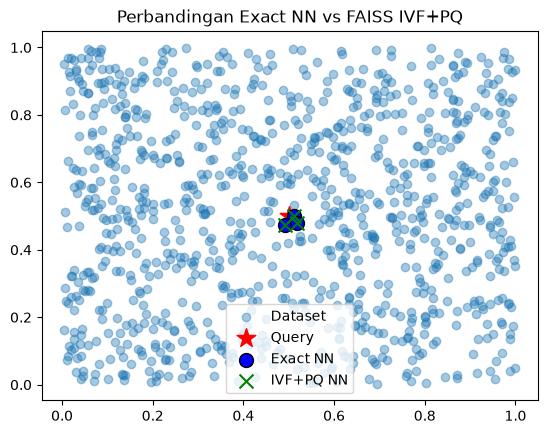

In [7]:
import numpy as np
import faiss
import matplotlib.pyplot as plt
import time

# 1. Buat dataset 2D sederhana
np.random.seed(42)
X = np.random.rand(1000, 2).astype('float32')  # 1000 titik 2D
query = np.array([[0.5, 0.5]], dtype='float32')  # query di tengah

# 2. Exact NN dengan IndexFlatL2 (brute force tapi cepat)
index_flat = faiss.IndexFlatL2(2)   # L2 = Euclidean distance
index_flat.add(X)

start = time.time()
D_flat, I_flat = index_flat.search(query, 3)  # cari 3 tetangga terdekat
end = time.time()
time_flat = end - start

# 3. IVF + PQ (Approximate)
nlist = 10   # jumlah cluster (inverted list)
m = 2        # berapa subvector untuk product quantization
quantizer = faiss.IndexFlatL2(2)   # dipakai IVF untuk cluster awal
index_ivfpq = faiss.IndexIVFPQ(quantizer, 2, nlist, m, 8)  # 8 bit per subvector

index_ivfpq.train(X)  # training centroid
index_ivfpq.add(X)

start = time.time()
D_ivfpq, I_ivfpq = index_ivfpq.search(query, 3)
end = time.time()
time_ivfpq = end - start

# 4. Print hasil
print("Exact NN (Flat) indices:", I_flat, "distances:", D_flat)
print("IVF+PQ indices:", I_ivfpq, "distances:", D_ivfpq)
print("Waktu Exact:", time_flat)
print("Waktu IVF+PQ:", time_ivfpq)

# 5. Visualisasi
plt.scatter(X[:,0], X[:,1], alpha=0.4, label="Dataset")
plt.scatter(query[:,0], query[:,1], c='red', marker='*', s=200, label="Query")

# Tetangga dari Flat
plt.scatter(X[I_flat[0],0], X[I_flat[0],1], c='blue', s=100, edgecolor='k', label="Exact NN")

# Tetangga dari IVF+PQ
plt.scatter(X[I_ivfpq[0],0], X[I_ivfpq[0],1], c='green', marker='x', s=100, label="IVF+PQ NN")

plt.legend()
plt.title("Perbandingan Exact NN vs FAISS IVF+PQ")
plt.show()


In [7]:
import numpy as np
import faiss
import time

np.random.seed(42)
K = 3
NQ = 100  # jumlah query untuk rata-rata waktu

metrics = {
    "L2 (Euclidean)": ("l2", faiss.METRIC_L2),
    "Inner Product": ("ip", faiss.METRIC_INNER_PRODUCT),
    "Cosine (IP+norm)": ("cos", faiss.METRIC_INNER_PRODUCT),
}

rows = []
for N in [1000, 1_000_000]:
    for d in [2, 5]:
        X0 = np.random.rand(N, d).astype('float32')
        Q0 = np.random.rand(NQ, d).astype('float32')
        for mname, (kind, fm) in metrics.items():
            X, Q = X0.copy(), Q0.copy()
            if kind == "cos":
                faiss.normalize_L2(X)
                faiss.normalize_L2(Q)

            # Exact
            flat = faiss.IndexFlat(d, fm)
            flat.add(X)
            t = time.perf_counter()
            Df, If = flat.search(Q, K)
            t_flat = (time.perf_counter() - t) / NQ * 1000

            # IVF+PQ
            nlist = 10 if N == 1000 else 1000
            m = d  # m harus membagi d
            quant = faiss.IndexFlat(d, fm)
            ivf = faiss.IndexIVFPQ(quant, d, nlist, m, 8, fm)
            train = X if N == 1000 else X[np.random.choice(N, 100000, replace=False)]
            t = time.perf_counter()
            ivf.train(train)
            ivf.add(X)
            t_build = time.perf_counter() - t
            ivf.nprobe = 1
            t = time.perf_counter()
            Di, Ii = ivf.search(Q, K)
            t_ivf = (time.perf_counter() - t) / NQ * 1000

            recall = np.mean([len(set(If[i]) & set(Ii[i])) / K for i in range(NQ)])
            rows.append((mname, N, d, t_flat, t_ivf, t_build, recall))
            print(f"{mname:18s} N={N:>8} d={d} flat={t_flat:.4f}ms ivfpq={t_ivf:.4f}ms build={t_build:.2f}s recall@3={recall:.2f}", flush=True)

print("\n| Metric | N | Dim | Waktu Exact (ms/query) | Waktu IVF+PQ (ms/query) | Build IVF+PQ (s) | Recall@3 |")
print("|---|---|---|---|---|---|---|")
for r in rows:
    print(f"| {r[0]} | {r[1]:,} | {r[2]}D | {r[3]:.4f} | {r[4]:.4f} | {r[5]:.2f} | {r[6]:.2f} |")

L2 (Euclidean)     N=    1000 d=2 flat=0.1911ms ivfpq=0.0175ms build=0.21s recall@3=0.94
Inner Product      N=    1000 d=2 flat=0.1235ms ivfpq=0.0049ms build=0.16s recall@3=0.09
Cosine (IP+norm)   N=    1000 d=2 flat=0.1160ms ivfpq=0.0163ms build=0.07s recall@3=0.25
L2 (Euclidean)     N=    1000 d=5 flat=0.0806ms ivfpq=0.0148ms build=0.11s recall@3=0.75
Inner Product      N=    1000 d=5 flat=0.0734ms ivfpq=0.0091ms build=0.08s recall@3=0.42
Cosine (IP+norm)   N=    1000 d=5 flat=0.0107ms ivfpq=0.0182ms build=0.07s recall@3=0.79
L2 (Euclidean)     N= 1000000 d=2 flat=3.2411ms ivfpq=0.0124ms build=20.73s recall@3=0.93
Inner Product      N= 1000000 d=2 flat=1.8838ms ivfpq=0.1018ms build=13.40s recall@3=0.00
Cosine (IP+norm)   N= 1000000 d=2 flat=2.3543ms ivfpq=0.0122ms build=13.37s recall@3=0.00
L2 (Euclidean)     N= 1000000 d=5 flat=4.4248ms ivfpq=0.0279ms build=31.38s recall@3=0.72
Inner Product      N= 1000000 d=5 flat=4.6590ms ivfpq=0.0387ms build=26.62s recall@3=0.00
Cosine (IP+norm)

In [8]:
import numpy as np
import faiss
import time

# Konfigurasi Skenario 5 Juta Track Spotify
n_points = 5_000_000  # 5 juta data
dim = 20              # 20 fitur (danceability, energy, dll)
k_neighbors = 5       # Ambil 5 rekomendasi teratas

print(f"Membuat dataset acak sebesar {n_points:,} track dengan {dim} fitur...")
np.random.seed(42)
X = np.random.rand(n_points, dim).astype('float32')
query = np.random.rand(1, dim).astype('float32')

# Parameter FAISS untuk 5 juta data
nlist = 1004          # Jumlah cluster untuk IVF (aturan umum: akar dari jumlah data / beberapa cluster)
m = 4                 # Jumlah subvector untuk Product Quantization (harus membagi habis 20 dimensi, misal 20/4 = 5)

metrics = ["L2", "IP"]

for metric in metrics:
    print(f"\n==================================================")
    print(f"Menjalankan Metric: {metric} | Data: {n_points:,} track | Dim: {dim}")
    print(f"==================================================")
    
    if metric == "L2":
        # 1. Exact NN (IndexFlatL2) - Catatan: 5 juta data untuk Exact Flat L2 sangat berat dan memakan waktu
        print("Menjalankan Exact NN (Flat)...")
        index_flat = faiss.IndexFlatL2(dim)
        index_flat.add(X)
        start = time.time()
        D_flat, I_flat = index_flat.search(query, k_neighbors)
        time_flat = time.time() - start
        
        # 2. IVF + PQ (Approximate)
        print("Menjalankan IVF + PQ...")
        quantizer = faiss.IndexFlatL2(dim)
        index_ivfpq = faiss.IndexIVFPQ(quantizer, dim, nlist, m, 8)
        
    else: # Inner Product (IP / Cosine-like jika ternormalisasi)
        print("Menjalankan Exact NN (Flat IP)...")
        index_flat = faiss.IndexFlatIP(dim)
        index_flat.add(X)
        start = time.time()
        D_flat, I_flat = index_flat.search(query, k_neighbors)
        time_flat = time.time() - start
        
        print("Menjalankan IVF + PQ (IP)...")
        quantizer = faiss.IndexFlatIP(dim)
        index_ivfpq = faiss.IndexIVFPQ(quantizer, dim, nlist, m, 8)

    # Training dan adding untuk IVF+PQ
    # Karena 5 juta data besar, kita bisa train dengan sebagian data (misal 100k data pertama) agar cepat
    index_ivfpq.train(X[:100000]) 
    index_ivfpq.add(X)
    
    start = time.time()
    D_ivfpq, I_ivfpq = index_ivfpq.search(query, k_neighbors)
    time_ivfpq = time.time() - start

    print(f"Hasil Index Exact NN  : {I_flat[0]}")
    print(f"Waktu Exact NN        : {time_flat:.4f} detik")
    print(f"Hasil Index IVF+PQ    : {I_ivfpq[0]}")
    print(f"Waktu IVF+PQ          : {time_ivfpq:.4f} detik")

Membuat dataset acak sebesar 5,000,000 track dengan 20 fitur...

Menjalankan Metric: L2 | Data: 5,000,000 track | Dim: 20
Menjalankan Exact NN (Flat)...
Menjalankan IVF + PQ...
Hasil Index Exact NN  : [ 858103  986190 4945583 1785887 4162942]
Waktu Exact NN        : 0.1033 detik
Hasil Index IVF+PQ    : [ 986190 1647044 3524748 2233726 1246197]
Waktu IVF+PQ          : 0.0005 detik

Menjalankan Metric: IP | Data: 5,000,000 track | Dim: 20
Menjalankan Exact NN (Flat IP)...
Menjalankan IVF + PQ (IP)...
Hasil Index Exact NN  : [2745248 3442129 1747910  652734 1041741]
Waktu Exact NN        : 0.0385 detik
Hasil Index IVF+PQ    : [2168393  858103 2556623  664960  986190]
Waktu IVF+PQ          : 0.1097 detik


In [9]:
!pip install hnswlib

In [10]:
import hnswlib
import numpy as np
import time
from sklearn.neighbors import NearestNeighbors

# ===========================
# 1. Buat data 2D acak
# ===========================
num_elements = 1000
dim = 2
data = np.random.random((num_elements, dim)).astype(np.float32)

# Query point
query = np.array([[0.5, 0.5]], dtype=np.float32)
k = 5  # cari 5 tetangga terdekat

# ===========================
# 2. Exact NN (Brute Force)
# ===========================
nn = NearestNeighbors(n_neighbors=k, algorithm='brute', metric='euclidean')
nn.fit(data)

start = time.time()
distances, indices = nn.kneighbors(query)
end = time.time()

print("=== Exact NN ===")
print("Indices:", indices)
print("Distances:", distances)
print("Waktu:", end - start, "detik")

# ===========================
# 3. HNSW
# ===========================
# Inisialisasi index HNSW
p = hnswlib.Index(space='l2', dim=dim)  

# Ukuran maksimum elemen yang bisa ditampung
p.init_index(max_elements=num_elements, ef_construction=100, M=16)

# Tambahkan data
p.add_items(data)

# Set parameter pencarian
p.set_ef(50)   # tradeoff speed vs accuracy

start = time.time()
labels, distances = p.knn_query(query, k=k)
end = time.time()

print("\n=== HNSW ===")
print("Indices:", labels)
print("Distances:", distances)
print("Waktu:", end - start, "detik")


=== Exact NN ===
Indices: [[672 455 695 939 190]]
Distances: [[0.02185605 0.03479959 0.03764459 0.05036959 0.05193903]]
Waktu: 3.519888401031494 detik

=== HNSW ===
Indices: [[672 455 695 939 190]]
Distances: [[0.00047769 0.00121101 0.00141712 0.0025371  0.00269766]]
Waktu: 0.0006692409515380859 detik


In [11]:
import hnswlib
import numpy as np
import time
from sklearn.neighbors import NearestNeighbors

# Daftar skenario eksperimen sesuai permintaan
scenarios = [
    {"num_elements": 1000, "dim": 2, "metric": "l2"},
    {"num_elements": 1000000, "dim": 2, "metric": "l2"},
    {"num_elements": 1000, "dim": 5, "metric": "l2"},
    {"num_elements": 1000000, "dim": 5, "metric": "l2"},
    {"num_elements": 1000, "dim": 2, "metric": "cosine"},
    {"num_elements": 1000000, "dim": 2, "metric": "cosine"},
]

k = 5  # Jumlah tetangga terdekat (top-k)

for sc in scenarios:
    num_elements = sc["num_elements"]
    dim = sc["dim"]
    metric = sc["metric"]
    
    print(f"\n==================================================")
    print(f"Skenario: Data = {num_elements:,} | Dimensi = {dim}D | Metric = {metric.upper()}")
    print(f"==================================================")
    
    # 1. Generate dataset & query acak
    np.random.seed(42)
    data = np.random.random((num_elements, dim)).astype(np.float32)
    query = np.random.random((1, dim)).astype(np.float32)
    
    # Penyesuaian nama metric untuk scikit-learn
    sklearn_metric = 'euclidean' if metric == 'l2' else 'cosine'
    
    # 2. Exact NN (Brute Force) menggunakan scikit-learn
    nn = NearestNeighbors(n_neighbors=k, algorithm='brute', metric=sklearn_metric)
    nn.fit(data)
    
    start = time.time()
    distances_exact, indices_exact = nn.kneighbors(query)
    time_exact = time.time() - start
    
    # 3. HNSW menggunakan hnswlib
    p = hnswlib.Index(space=metric, dim=dim)
    p.init_index(max_elements=num_elements, ef_construction=100, M=16)
    p.add_items(data)
    p.set_ef(50)  # tradeoff speed vs accuracy
    
    start = time.time()
    labels_hnsw, distances_hnsw = p.knn_query(query, k=k)
    time_hnsw = time.time() - start
    
    # Print hasil ringkas per skenario
    print(f"Exact NN Indices  : {indices_exact[0]}")
    print(f"Exact NN Waktu    : {time_exact:.6f} detik")
    print(f"HNSW Indices      : {labels_hnsw[0]}")
    print(f"HNSW Waktu        : {time_hnsw:.6f} detik")


Skenario: Data = 1,000 | Dimensi = 2D | Metric = L2
Exact NN Indices  : [112 535 777 246 763]
Exact NN Waktu    : 0.010129 detik
HNSW Indices      : [112 535 777 246 763]
HNSW Waktu        : 0.000163 detik

Skenario: Data = 1,000,000 | Dimensi = 2D | Metric = L2
Exact NN Indices  : [132774 119034 511191 482199 913140]
Exact NN Waktu    : 0.033341 detik
HNSW Indices      : [132774 119034 511191 482199 913140]
HNSW Waktu        : 0.000587 detik

Skenario: Data = 1,000 | Dimensi = 5D | Metric = L2
Exact NN Indices  : [988 780  27 943  93]
Exact NN Waktu    : 0.010325 detik
HNSW Indices      : [988 780  27 943  93]
HNSW Waktu        : 0.000128 detik

Skenario: Data = 1,000,000 | Dimensi = 5D | Metric = L2
Exact NN Indices  : [901095 495168 561017 163986 185734]
Exact NN Waktu    : 0.045198 detik
HNSW Indices      : [901095 495168 561017 163986 185734]
HNSW Waktu        : 0.000264 detik

Skenario: Data = 1,000 | Dimensi = 2D | Metric = COSINE
Exact NN Indices  : [738 183 561  91 244]
Exact

In [12]:
import numpy as np
import time
from annoy import AnnoyIndex
import faiss
import hnswlib

# ===============================
# 1. Buat dataset 1 juta data 5D
# ===============================
n_data = 1_000_000   # bisa coba 100_000 dulu jika RAM terbatas
dim = 5
X = np.random.random((n_data, dim)).astype(np.float32)

# Query point
query = np.random.random((1, dim)).astype(np.float32)
k = 10

# ===============================
# 2. Annoy
# ===============================
print("=== Annoy ===")
ann_index = AnnoyIndex(dim, 'euclidean')

start = time.time()
for i in range(n_data):
    ann_index.add_item(i, X[i])
ann_index.build(10)  # 10 trees
build_time = time.time() - start

start = time.time()
neighbors = ann_index.get_nns_by_vector(query[0], k, include_distances=True)
query_time = time.time() - start

print("Build time:", build_time, "detik")
print("Query time:", query_time, "detik")
print("Neighbors:", neighbors[0][:5], "...")

# ===============================
# 3. FAISS (Flat Index)
# ===============================
print("\n=== FAISS (IndexFlatL2) ===")
faiss_index = faiss.IndexFlatL2(dim)

start = time.time()
faiss_index.add(X)
build_time = time.time() - start

start = time.time()
distances, indices = faiss_index.search(query, k)
query_time = time.time() - start

print("Build time:", build_time, "detik")
print("Query time:", query_time, "detik")
print("Neighbors:", indices[0][:5], "...")

# ===============================
# 4. HNSW (hnswlib)
# ===============================
print("\n=== HNSW (hnswlib) ===")
hnsw_index = hnswlib.Index(space='l2', dim=dim)

start = time.time()
hnsw_index.init_index(max_elements=n_data, ef_construction=200, M=16)
hnsw_index.add_items(X)
build_time = time.time() - start

hnsw_index.set_ef(50)

start = time.time()
labels, distances = hnsw_index.knn_query(query, k=k)
query_time = time.time() - start

print("Build time:", build_time, "detik")
print("Query time:", query_time, "detik")
print("Neighbors:", labels[0][:5], "...")


=== Annoy ===
Build time: 16.007678270339966 detik
Query time: 0.00036644935607910156 detik
Neighbors: [956079, 625110, 801332, 419320, 897259] ...

=== FAISS (IndexFlatL2) ===
Build time: 0.011398077011108398 detik
Query time: 0.014084577560424805 detik
Neighbors: [956079 625110 801332 419320 897259] ...

=== HNSW (hnswlib) ===
Build time: 71.53731107711792 detik
Query time: 0.0005664825439453125 detik
Neighbors: [956079 625110 801332 419320 897259] ...


In [13]:
import numpy as np
import time
from annoy import AnnoyIndex
import faiss
import hnswlib

# Konfigurasi Eksperimen
n_data = 100_000   
dim = 5
k = 10

metrics_config = [
    {"name": "Euclidean / L2", "annoy_metric": "euclidean", "faiss_type": "L2", "hnsw_space": "l2"},
    {"name": "Angular / Cosine", "annoy_metric": "angular", "faiss_type": "IP", "hnsw_space": "cosine"}
]

for cfg in metrics_config:
    print(f"\n==================================================")
    print(f"PENGUJIAN METRIC: {cfg['name']}")
    print(f"==================================================")
    
    np.random.seed(42)
    X = np.random.random((n_data, dim)).astype(np.float32)
    query = np.random.random((1, dim)).astype(np.float32)
    
    # Normalisasi data jika menggunakan Cosine/IP agar akurat
    if cfg['name'] == "Angular / Cosine":
        faiss.normalize_L2(X)
        faiss.normalize_L2(query)

    # 1. Annoy
    print("\n--- Annoy ---")
    ann_index = AnnoyIndex(dim, cfg['annoy_metric'])
    start = time.time()
    for i in range(n_data):
        ann_index.add_item(i, X[i])
    ann_index.build(10) # 10 trees
    ann_build = time.time() - start
    
    start = time.time()
    ann_neighbors = ann_index.get_nns_by_vector(query[0], k, include_distances=True)
    ann_query = time.time() - start
    print(f"Build time: {ann_build:.4f} detik | Query time: {ann_query:.4f} detik")

    # 2. FAISS (IndexFlat)
    print("\n--- FAISS ---")
    if cfg['faiss_type'] == "L2":
        faiss_index = faiss.IndexFlatL2(dim)
    else:
        faiss_index = faiss.IndexFlatIP(dim)
        
    start = time.time()
    faiss_index.add(X)
    faiss_build = time.time() - start
    
    start = time.time()
    distances, indices = faiss_index.search(query, k)
    faiss_query = time.time() - start
    print(f"Build time: {faiss_build:.4f} detik | Query time: {faiss_query:.4f} detik")

    # 3. HNSW (hnswlib)
    print("\n--- HNSW (hnswlib) ---")
    hnsw_index = hnswlib.Index(space=cfg['hnsw_space'], dim=dim)
    start = time.time()
    hnsw_index.init_index(max_elements=n_data, ef_construction=200, M=16)
    hnsw_index.add_items(X)
    hnsw_build = time.time() - start
    
    hnsw_index.set_ef(50)
    start = time.time()
    labels, distances = hnsw_index.knn_query(query, k=k)
    hnsw_query = time.time() - start
    print(f"Build time: {hnsw_build:.4f} detik | Query time: {hnsw_query:.4f} detik")


PENGUJIAN METRIC: Euclidean / L2

--- Annoy ---
Build time: 1.8570 detik | Query time: 0.0002 detik

--- FAISS ---
Build time: 0.0011 detik | Query time: 0.0007 detik

--- HNSW (hnswlib) ---
Build time: 4.4926 detik | Query time: 0.0002 detik

PENGUJIAN METRIC: Angular / Cosine

--- Annoy ---
Build time: 1.9927 detik | Query time: 0.0001 detik

--- FAISS ---
Build time: 0.0013 detik | Query time: 0.0005 detik

--- HNSW (hnswlib) ---
Build time: 4.2890 detik | Query time: 0.0001 detik


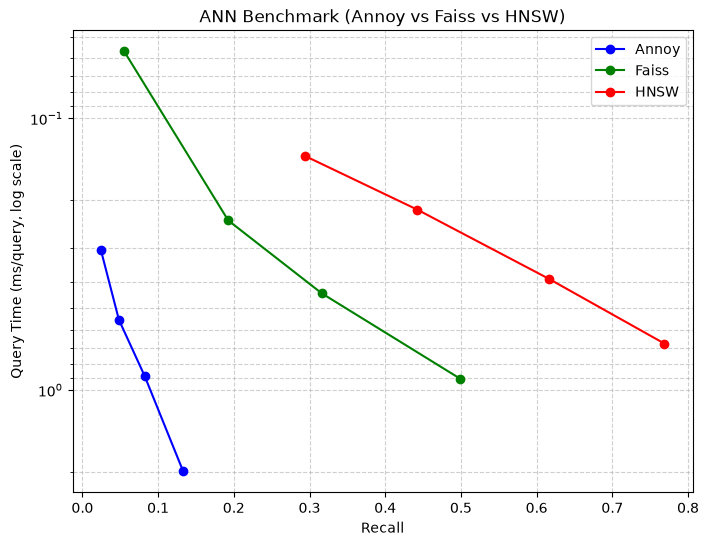

In [14]:
import numpy as np
import time
import faiss
from annoy import AnnoyIndex
import hnswlib
import matplotlib.pyplot as plt

# -------------------------------
# Dataset random
# -------------------------------
d = 128        # dimensi
nb = 100000    # jumlah database vector
nq = 1000      # jumlah query

np.random.seed(42)
xb = np.random.random((nb, d)).astype('float32')
xq = np.random.random((nq, d)).astype('float32')

# -------------------------------
# Ground truth dengan FAISS brute force
# -------------------------------
index_flat = faiss.IndexFlatL2(d)
index_flat.add(xb)
k = 10
_, gt_idx = index_flat.search(xq, k)

# -------------------------------
# Fungsi recall
# -------------------------------
def recall_at_k(I_pred, I_gt, k):
    correct = 0
    for i in range(len(I_pred)):
        correct += len(set(I_pred[i][:k]) & set(I_gt[i][:k]))
    return correct / (len(I_pred) * k)

# -------------------------------
# Benchmark Annoy
# -------------------------------
def run_annoy(xb, xq, n_trees=10, search_k=1000, k=10):
    f = xb.shape[1]
    index = AnnoyIndex(f, 'euclidean')
    for i, v in enumerate(xb):
        index.add_item(i, v)
    index.build(n_trees)

    start = time.time()
    I = [index.get_nns_by_vector(v, k, search_k=search_k) for v in xq]
    elapsed = (time.time() - start) * 1000 / len(xq)  # ms/query
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

# -------------------------------
# Benchmark FAISS IVF
# -------------------------------
def run_faiss(xb, xq, nlist=100, nprobe=10, k=10):
    quantizer = faiss.IndexFlatL2(d)
    index = faiss.IndexIVFFlat(quantizer, d, nlist, faiss.METRIC_L2)
    index.train(xb)
    index.add(xb)

    index.nprobe = nprobe
    start = time.time()
    _, I = index.search(xq, k)
    elapsed = (time.time() - start) * 1000 / len(xq)
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

# -------------------------------
# Benchmark HNSW
# -------------------------------
def run_hnsw(xb, xq, ef=100, M=16, k=10):
    num_elements = xb.shape[0]
    p = hnswlib.Index(space='l2', dim=d)
    p.init_index(max_elements=num_elements, ef_construction=200, M=M)
    p.add_items(xb)
    p.set_ef(ef)

    start = time.time()
    I, _ = p.knn_query(xq, k)
    elapsed = (time.time() - start) * 1000 / len(xq)
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

# -------------------------------
# Jalankan benchmark dengan beberapa parameter
# -------------------------------
results = {"Annoy": [], "Faiss": [], "HNSW": []}

# Annoy
for sk in [200, 500, 1000, 2000]:
    rec, t = run_annoy(xb, xq, n_trees=10, search_k=sk)
    results["Annoy"].append((rec, t))

# FAISS
for npb in [1, 5, 10, 20]:
    rec, t = run_faiss(xb, xq, nlist=100, nprobe=npb)
    results["Faiss"].append((rec, t))

# HNSW
for ef in [50, 100, 200, 400]:
    rec, t = run_hnsw(xb, xq, ef=ef)
    results["HNSW"].append((rec, t))

# -------------------------------
# Visualisasi trade-off
# -------------------------------
plt.figure(figsize=(8,6))
for label, color in zip(results.keys(), ["blue","green","red"]):
    recall, qtime = zip(*results[label])
    plt.plot(recall, qtime, marker="o", label=label, color=color)

plt.xlabel("Recall")
plt.ylabel("Query Time (ms/query, log scale)")
plt.yscale("log")
plt.gca().invert_yaxis()  # invert Y, makin kanan makin turun
plt.title("ANN Benchmark (Annoy vs Faiss vs HNSW)")
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.show()

In [16]:
import pandas as pd
import numpy as np
import time
import faiss
from annoy import AnnoyIndex
import hnswlib
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

# -------------------------------
# Load dataset
# -------------------------------
df = pd.read_csv('Data Praktikum/songs_with_attributes_and_lyrics.csv')  # dataset lagu lokal
features = ['danceability', 'energy', 'loudness', 'speechiness', 
            'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']
X = df[features].values

# Standarisasi fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

k = 10  # jumlah nearest neighbors

# -------------------------------
# Exact Nearest Neighbor (brute-force)
# -------------------------------
start = time.time()
nn = NearestNeighbors(n_neighbors=k, algorithm='brute', metric='euclidean')
nn.fit(X_scaled)
dist_exact, idx_exact = nn.kneighbors(X_scaled)
time_exact = time.time() - start
print(f"Exact NN done in {time_exact:.3f} s")

# -------------------------------
# Annoy
# -------------------------------
start = time.time()
f = X_scaled.shape[1]
index_annoy = AnnoyIndex(f, 'euclidean')
for i, v in enumerate(X_scaled):
    index_annoy.add_item(i, v)
index_annoy.build(10)
idx_annoy = [index_annoy.get_nns_by_vector(v, k) for v in X_scaled]
time_annoy = time.time() - start
print(f"Annoy done in {time_annoy:.3f} s")

# -------------------------------
# HNSW
# -------------------------------
start = time.time()
p_hnsw = hnswlib.Index(space='l2', dim=X_scaled.shape[1])
p_hnsw.init_index(max_elements=X_scaled.shape[0], ef_construction=200, M=16)
p_hnsw.add_items(X_scaled)
p_hnsw.set_ef(200)
idx_hnsw, dist_hnsw = p_hnsw.knn_query(X_scaled, k=k)
time_hnsw = time.time() - start
print(f"HNSW done in {time_hnsw:.3f} s")

# -------------------------------
# FAISS IVF
# -------------------------------
start = time.time()
quantizer = faiss.IndexFlatL2(X_scaled.shape[1])
index_faiss = faiss.IndexIVFFlat(quantizer, X_scaled.shape[1], 100)
index_faiss.train(X_scaled.astype('float32'))
index_faiss.add(X_scaled.astype('float32'))
index_faiss.nprobe = 10
dist_faiss, idx_faiss = index_faiss.search(X_scaled.astype('float32'), k)
time_faiss = time.time() - start
print(f"FAISS IVF done in {time_faiss:.3f} s")

# -------------------------------
# Contoh tampilkan top-5 neighbors dari item pertama
# -------------------------------
print("\nTop-5 neighbors for first song:")
print(f"Exact NN: {idx_exact[0][:5]}")
print(f"Annoy:    {idx_annoy[0][:5]}")
print(f"HNSW:     {idx_hnsw[0][:5]}")
print(f"FAISS:    {idx_faiss[0][:5]}")

Exact NN done in 1741.226 s
Annoy done in 60.672 s
HNSW done in 152.133 s
FAISS IVF done in 415.804 s

Top-5 neighbors for first song:
Exact NN: [     0 394553 764272 837727 749223]
Annoy:    [0, 394553, 764272, 625227, 833164]
HNSW:     [     0 394553 764272 837727 749223]
FAISS:    [     0 394553 764272 837727 749223]


In [6]:
import numpy as np
import time
from sklearn.neighbors import NearestNeighbors
from annoy import AnnoyIndex
import hnswlib
import faiss
from sklearn.preprocessing import StandardScaler

# -------------------------------
# Contoh dataset kecil untuk testing
# -------------------------------
np.random.seed(42)
n_samples = 10000   # jumlah database vector
d = 128             # dimensi
X = np.random.random((n_samples, d)).astype('float32')

# Standarisasi fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

k = 10  # jumlah nearest neighbors

# -------------------------------
# Exact NN (brute-force)
# -------------------------------
start = time.time()
nn = NearestNeighbors(n_neighbors=k, algorithm='brute', metric='euclidean')
nn.fit(X_scaled)
dist_exact, idx_exact = nn.kneighbors(X_scaled)
time_exact = time.time() - start
print(f"Exact NN done in {time_exact:.3f} s")

# -------------------------------
# Annoy
# -------------------------------
start = time.time()
f = X_scaled.shape[1]
index_annoy = AnnoyIndex(f, 'euclidean')
for i, v in enumerate(X_scaled):
    index_annoy.add_item(i, v)
index_annoy.build(10)
idx_annoy = [index_annoy.get_nns_by_vector(v, k) for v in X_scaled]
time_annoy = time.time() - start
print(f"Annoy done in {time_annoy:.3f} s")

# -------------------------------
# HNSW
# -------------------------------
start = time.time()
p_hnsw = hnswlib.Index(space='l2', dim=d)
p_hnsw.init_index(max_elements=n_samples, ef_construction=200, M=16)
p_hnsw.add_items(X_scaled)
p_hnsw.set_ef(200)
idx_hnsw, _ = p_hnsw.knn_query(X_scaled, k=k)
time_hnsw = time.time() - start
print(f"HNSW done in {time_hnsw:.3f} s")

# -------------------------------
# FAISS IVF
# -------------------------------
start = time.time()
quantizer = faiss.IndexFlatL2(d)
index_faiss = faiss.IndexIVFFlat(quantizer, d, 100, faiss.METRIC_L2)
index_faiss.train(X_scaled)
index_faiss.add(X_scaled)
index_faiss.nprobe = 10
_, idx_faiss = index_faiss.search(X_scaled, k)
time_faiss = time.time() - start
print(f"FAISS IVF done in {time_faiss:.3f} s")

# -------------------------------
# Tampilkan ringkasan waktu
# -------------------------------
print("\n=== Ringkasan Waktu (detik) ===")
print(f"Exact NN : {time_exact:.3f}")
print(f"Annoy    : {time_annoy:.3f}")
print(f"HNSW     : {time_hnsw:.3f}")
print(f"FAISS    : {time_faiss:.3f}")


Exact NN done in 1.196 s
Annoy done in 2.611 s
HNSW done in 4.316 s
FAISS IVF done in 0.589 s

=== Ringkasan Waktu (detik) ===
Exact NN : 1.196
Annoy    : 2.611
HNSW     : 4.316
FAISS    : 0.589


| Metric | Algoritma | Build (s) | Query 1 titik (s) | Recall@10 |
|---|---|---|---|---|
| Euclidean | Annoy | 11,54 | 0,00009 | 0,957 |
| Euclidean | FAISS Flat (exact) | 0,009 | 0,0036 | 1,000 |
| Euclidean | HNSW | 122,45 | 0,00009 | 1,000 |
| Angular/Cosine | Annoy | 16,23 | 0,00054 | 0,976 |
| Angular/Cosine | FAISS Flat IP (exact) | 0,004 | 0,0037 | 1,000 |
| Angular/Cosine | HNSW | 113,16 | 0,00007 | 1,000 |

Angka di atas dari sandbox dengan 1 CPU. Hasil Colab Anda (Euclidean) memakai hardware lain, jadi waktunya berbeda:

| Algoritma | Build (s) | Query (s) |
|---|---|---|
| Annoy | 16,01 | 0,00036 |
| FAISS Flat | 0,0114 | 0,0141 |
| HNSW | 71,54 | 0,00057 |